# M D 2 (max 200 m)

Twenty vessel arrivals, two service slots and a shared 200 m quay. The only Excel input is the **info** worksheet; all visits are generated below. The data worksheet is not read.

## 1. Read vessel definitions

All times in `info` are **days**, and lengths are metres. `AT` is the first arrival time (or its mean when stochastic); `IAT` is each vessel's return interval (or its mean). Service time is calculated from `loading + unloading`, not the redundant `ST` column. The generated simulation tables use **hours**.

In [1]:
import openqtsim
import pandas as pd
from IPython.display import display

info = pd.read_excel('OpenQTSim - D D 1 example.xlsx', sheet_name='info')
info

,name,IAT,ST,AT,length,maxwait,unloading,loading
0,Yellowstar,7,3,2,80,1,2,1
1,ABC,30,7,12,100,2,4,3
2,Oil Trade,18,2,5,100,1,2,0
3,Gen. Cargo Trade,60,4,24,160,2,3,1
4,Fruit Trade,10,6,9,90,0,3,3
5,United,16,5,2,80,2,1,4


## 2. Choose distributions and an arrival limit

Use **exactly one** stopping limit: `nr_arrivals=20` and `max_duration_days=None`, or `nr_arrivals=None` and e.g. `max_duration_days=60`. A duration limit includes arrivals at the boundary; service and waiting then drain to completion or reneging, even beyond that limit.

`D` uses fixed times. `M` samples independent negative-exponential times. Stochastic first arrivals have mean `AT`; subsequent return intervals have mean `IAT`, separately for each vessel. Stochastic service has vessel-specific mean `loading + unloading`. Arrival and service seeds must be different; changing the service seed does not change the generated arrivals.

These are vessel-specific renewal streams and service mixtures, not necessarily a homogeneous textbook M/M/2 queue. Samples are generated in advance and replayed through the simulator's deterministic-table interface to preserve vessel identity.

In [2]:
example_title = "M D 2 (max 200 m)"
nr_arrivals = 20
max_duration_days = None
arrival_distribution = "M"
service_distribution = "D"
arrival_seed = 12
service_seed = 13
c = 2
quay_length = 200

## 3. Generate the arrival and service tables

Each row represents one visit. Visits are ordered by arrival time, with ties resolved by the original info-sheet row order. The simulator pairs both tables by row position. Subsequent visits remain scheduled even if an earlier visit reneges. `maxwait` is converted from days to hours, without randomisation.

In [3]:
arrival_table, service_table = openqtsim.generate_vessel_tables(
    info,
    nr_arrivals=nr_arrivals,
    max_duration_days=max_duration_days,
    arrival_distribution=arrival_distribution,
    service_distribution=service_distribution,
    arrival_seed=arrival_seed,
    service_seed=service_seed,
)
print(f'Generated {len(arrival_table)} vessel arrivals; all table times are hours.')
display(arrival_table)
display(service_table)

Generated 20 vessel arrivals; all table times are hours.


,name,vessel_id,visit,IAT,AT,length,maxwait
0,Oil Trade,3,1,60.954374,60.954374,100,24
1,Yellowstar,1,1,88.785292,149.739666,80,24
2,United,6,1,2.286994,152.026660,80,48
3,ABC,2,1,36.976699,189.003359,100,48
4,Fruit Trade,5,1,26.682161,215.685520,90,0
5,Yellowstar,1,2,15.306018,230.991539,80,24
6,Fruit Trade,5,2,43.046251,274.037790,90,0
7,United,6,2,5.487345,279.525135,80,48
8,Yellowstar,1,3,29.091537,308.616672,80,24
9,Gen. Cargo Trade,4,1,86.131042,394.747714,160,48


,name,ST
0,Oil Trade,48.0
1,Yellowstar,72.0
2,United,120.0
3,ABC,168.0
4,Fruit Trade,144.0
5,Yellowstar,72.0
6,Fruit Trade,144.0
7,United,120.0
8,Yellowstar,72.0
9,Gen. Cargo Trade,96.0


## 4. Simulate the quay

Admission requires both a free service slot and enough remaining length. Strict FIFO prevents bypassing a blocked vessel. A vessel that cannot start by `AT + maxwait` reneges and leaves the queue permanently. Service starting exactly at the deadline is allowed; zero patience allows immediate service only.

In [4]:
if arrival_table.empty:
    raise ValueError('No arrivals within the selected duration; increase the limit.')
A = openqtsim.ArrivalProcess('D', arrival_table)
S = openqtsim.ServiceProcess('D', service_table)
q = openqtsim.Queue(A, S, c=c, quay_length=quay_length)
sim = openqtsim.Simulation(q)
sim.run(len(arrival_table))
summary = sim.get_stats()

Departures: 10 served, 10 reneged
Waiting time in units of service time: 0.1584
Observation horizon: 0 to 868.4797 hours

Rho_system: system utilisation: 0.7234
Rho_server: server utilisation: 0.5389
P_0: probability nobody in the system: 0.2766

L_s: average nr of customers in the system: 1.4192
L_q: average nr of customers in the queue: 0.3414
W_s: average time spent in the system: 61.6261
W_q: average time spent in the queue: 14.8261

IAT: average inter arrival time: 41.0240
ST: average service time: 93.6000



(<Figure size 1400x700 with 1 Axes>,
 <Axes: xlabel='Time (hours)', ylabel='Nr. of customers'>)

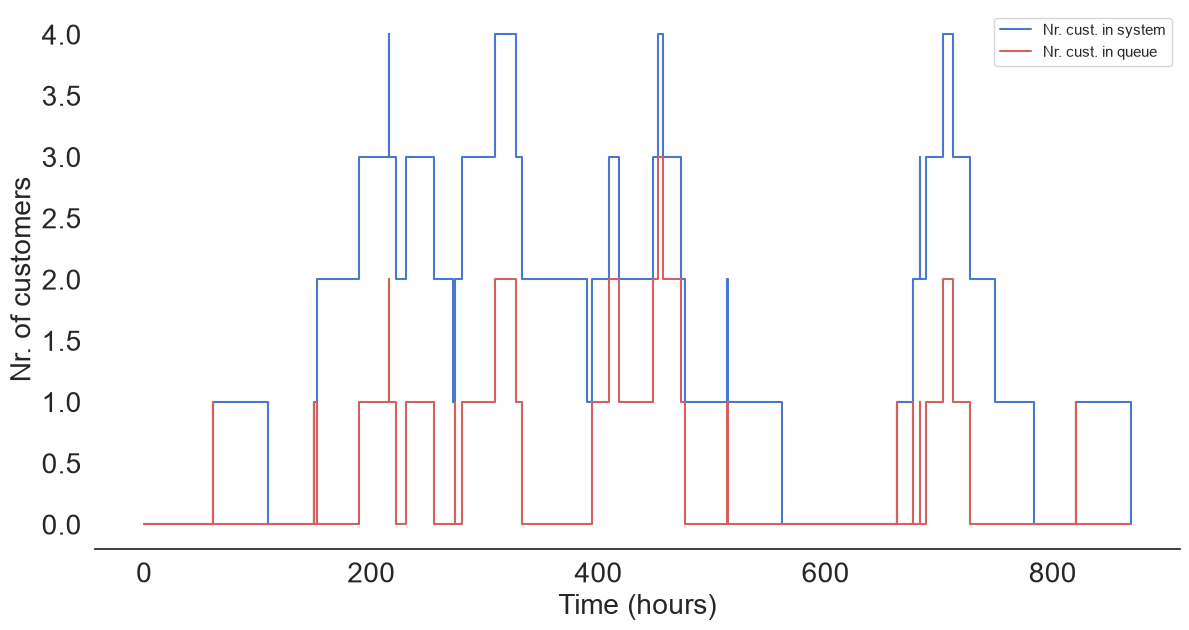

In [5]:
sim.plot_system_state()

In [6]:
df, df_sys = sim.return_log()
display(df)
display(df_sys.head(10))

,c_id,name,length,maxwait,status,departure,IAT,ST,AT,TSB,TSE,TCSS,TCWQ,ITS,s_id
0,1,Oil Trade,100,24,served,108.954374,60.954374,48.0,60.954374,60.954374,108.954374,48.000000,0.000000,60.954374,1.0
2,2,Yellowstar,80,24,served,221.739666,88.785292,72.0,149.739666,149.739666,221.739666,72.000000,0.000000,149.739666,2.0
4,3,United,80,48,served,272.026660,2.286994,120.0,152.026660,152.026660,272.026660,120.000000,0.000000,43.072285,1.0
7,4,ABC,100,48,served,389.739666,36.976699,168.0,189.003359,221.739666,389.739666,200.736307,32.736307,0.000000,2.0
1,5,Fruit Trade,90,0,reneged,215.685520,26.682161,NaN,215.685520,NaN,NaN,0.000000,0.000000,NaN,NaN
3,6,Yellowstar,80,24,reneged,254.991539,15.306018,NaN,230.991539,NaN,NaN,24.000000,24.000000,NaN,NaN
8,7,Fruit Trade,90,0,served,418.037790,43.046251,144.0,274.037790,274.037790,418.037790,144.000000,0.000000,2.011130,1.0
5,8,United,80,48,reneged,327.525135,5.487345,NaN,279.525135,NaN,NaN,48.000000,48.000000,NaN,NaN
6,9,Yellowstar,80,24,reneged,332.616672,29.091537,NaN,308.616672,NaN,NaN,24.000000,24.000000,NaN,NaN
12,10,Gen. Cargo Trade,160,48,served,514.037790,86.131042,96.0,394.747715,418.037790,514.037790,119.290076,23.290076,28.298124,2.0


,t,c_s,c_q
0,0.000000,0,0
1,60.954374,1,1
2,60.954374,1,0
3,108.954374,0,0
4,149.739666,1,1
5,149.739666,1,0
6,152.026660,2,1
7,152.026660,2,0
8,189.003359,3,1
9,215.685520,4,2


## 5. Gantt chart: arrival, waiting, service and reneging

One row per vessel visit, labelled by vessel name. Orange is waiting, blue is actual service, a green cross marks departure after service, and a **red cross** marks reneging. Reneged visits have no service bar. Hover labels show at most two decimals in hours, with days in parentheses. The table below includes status and actual departure time.

In [7]:
import plotly.graph_objects as go

customers = df.sort_values(["AT", "c_id"]).copy()
customers["wait_end"] = customers["TSB"].fillna(customers["departure"])
customer_rows = "Customer " + customers["c_id"].astype(str)
customer_labels = customer_rows.copy()
if "name" in customers.columns:
    names = customers["name"].fillna("").astype(str).str.strip()
    customer_labels = names.where(names.ne(""), customer_rows)
def hover_time(hours):
    hours_text = f"{hours:.2f}".rstrip("0").rstrip(".")
    days_text = f"{hours / 24:.2f}".rstrip("0").rstrip(".")
    return f"{hours_text} h ({days_text} days)"

fig = go.Figure()

for phase, start, end, color in [
    ("Waiting", "AT", "wait_end", "#E69F00"),
    ("Service", "TSB", "TSE", "#0072B2"),
]:
    mask = customers[start].notna() & customers[end].notna()
    fig.add_trace(go.Bar(
        name=phase, y=customer_rows[mask], text=customer_labels[mask], textposition="none",
        x=customers.loc[mask, end] - customers.loc[mask, start], base=customers.loc[mask, start],
        orientation="h", marker_color=color,
        customdata=list(zip(
            customers.loc[mask, start].map(hover_time),
            customers.loc[mask, end].map(hover_time),
            (customers.loc[mask, end] - customers.loc[mask, start]).map(hover_time),
        )),
        hovertemplate=("%{text}<br>Start: %{customdata[0]}"
                       "<br>End: %{customdata[1]}"
                       "<br>Duration: %{customdata[2]}<extra>%{fullData.name}</extra>"),
    ))

for event, column, symbol, color, size, status in [
    ("Arrival", "AT", "circle-open", "#333333", 12, None),
    ("Departure", "TSE", "x", "#009E73", 9, "served"),
    ("Service start", "TSB", "diamond", "#CC79A7", 6, "served"),
    ("Reneged", "departure", "x", "red", 12, "reneged"),
]:
    mask = customers[column].notna()
    if status is not None:
        mask &= customers["status"].eq(status)
    fig.add_trace(go.Scatter(
        name=event, x=customers.loc[mask, column], y=customer_rows[mask], text=customer_labels[mask], mode="markers",
        marker=dict(symbol=symbol, color=color, size=size),
        customdata=customers.loc[mask, column].map(hover_time),
        hovertemplate="%{text}<br>Time: %{customdata}<extra>%{fullData.name}</extra>",
    ))

horizon = customers["departure"].max()
fig.update_layout(
    title=f"{example_title}: {len(customers)} vessel arrivals",
    barmode="overlay", template="plotly_white", height=750,
    xaxis_title="Time since simulation start (hours)",
    yaxis_title="Customer (arrival order)", legend_title_text="Phase / event",
)
fig.update_yaxes(categoryorder="array", categoryarray=customer_rows.tolist(), autorange="reversed",
                 tickmode="array", tickvals=customer_rows.tolist(), ticktext=customer_labels.tolist())
fig.update_xaxes(range=[0, horizon * 1.03])
fig.show()
customers[["c_id", "name", "length", "maxwait", "status", "AT", "TSB", "TSE", "departure", "TCWQ", "ST", "TCSS", "s_id"]]

,c_id,name,length,maxwait,status,AT,TSB,TSE,departure,TCWQ,ST,TCSS,s_id
0,1,Oil Trade,100,24,served,60.954374,60.954374,108.954374,108.954374,0.000000,48.0,48.000000,1.0
2,2,Yellowstar,80,24,served,149.739666,149.739666,221.739666,221.739666,0.000000,72.0,72.000000,2.0
4,3,United,80,48,served,152.026660,152.026660,272.026660,272.026660,0.000000,120.0,120.000000,1.0
7,4,ABC,100,48,served,189.003359,221.739666,389.739666,389.739666,32.736307,168.0,200.736307,2.0
1,5,Fruit Trade,90,0,reneged,215.685520,NaN,NaN,215.685520,0.000000,NaN,0.000000,NaN
3,6,Yellowstar,80,24,reneged,230.991539,NaN,NaN,254.991539,24.000000,NaN,24.000000,NaN
8,7,Fruit Trade,90,0,served,274.037790,274.037790,418.037790,418.037790,0.000000,144.0,144.000000,1.0
5,8,United,80,48,reneged,279.525135,NaN,NaN,327.525135,48.000000,NaN,48.000000,NaN
6,9,Yellowstar,80,24,reneged,308.616672,NaN,NaN,332.616672,24.000000,NaN,24.000000,NaN
12,10,Gen. Cargo Trade,160,48,served,394.747715,418.037790,514.037790,514.037790,23.290076,96.0,119.290076,2.0
